# 02 · Week 2: the word translator on MaleCNS
Brain: MaleCNS v1.0 brain-only LIF (monoamines removed, w × 0.581, rate APL). Three versions:
- **base**: as ported.
- **calib**: chemical cholinergic LN→PN = 0 plus eLN–PN gap junctions (c0 = 0.2, 2 mV spikelets). Removes the persistent attractor.
- **shuffle**: calib with the chemical matrix shuffled, keeping each neuron's in/out degree and output sign.

17 words × 10 Poisson seeds, 500 ms at 150 Hz. Readout: L2 logistic regression on log(1 + spike count) per neuron. *Learned:* only this readout. The connectome is never trained.

Loads `results/readout/readout_summary.json` and `trials_*.npz`; does not re-run the 510 trials.

In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
R = ROOT / 'results'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
s = json.load(open(R/'readout/readout_summary.json')); W = s['words']
rows = []
for k, v in s['results'].items():
    model, win, feat = k.split('/')
    rows.append(dict(model=model, window={'stim': '0-0.5 s (stimulus)', 'post': '0.5-1.0 s (after)'}[win],
                     features={'all': 'all non-sensory', 'motor': 'DNs + MNs'}[feat],
                     test_split=v['acc_split'], leave_one_seed_out=v['acc_loso'], n_features=v.get('n_features')))
t = pd.DataFrame(rows); print(f"chance = {s['chance']:.3f}")
t.pivot_table(index=['window', 'features'], columns='model', values='leave_one_seed_out').round(3)

chance = 0.059


model                                base  calib  shuffle
window             features                              
0-0.5 s (stimulus) DNs + MNs        0.976  0.941    0.847
                   all non-sensory  1.000  1.000    1.000
0.5-1.0 s (after)  DNs + MNs        0.524  0.682    0.206
                   all non-sensory  0.694  0.935    0.700

**The main lesson of Phase 1:** the shuffled brain also decodes all 17 words at 100% from all neurons. A linear readout of a driven network works with almost any wiring. The real wiring shows up only in the motor-only readout and after the stimulus ends.

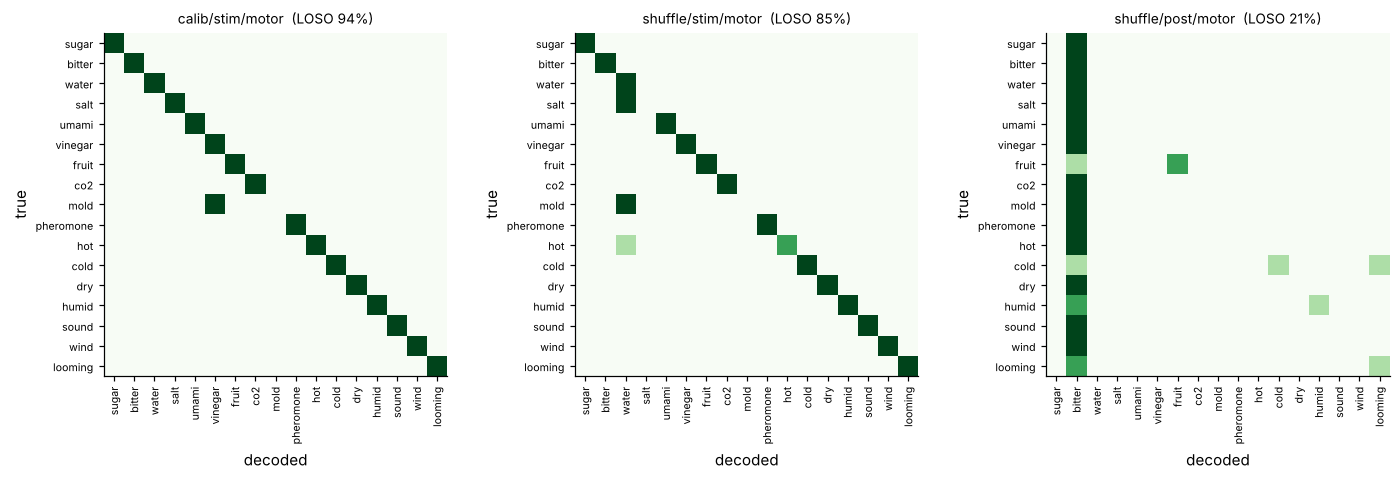

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, k in zip(axs, ['calib/stim/motor', 'shuffle/stim/motor', 'shuffle/post/motor']):
    C = np.array(s['results'][k]['confusion']); ax.imshow(C, cmap='Greens')
    ax.set_xticks(range(17), W, rotation=90, fontsize=7); ax.set_yticks(range(17), W, fontsize=7)
    ax.set_title(f"{k}  (LOSO {s['results'][k]['acc_loso']:.0%})", fontsize=9); ax.set_xlabel('decoded'); ax.set_ylabel('true')
plt.tight_layout()

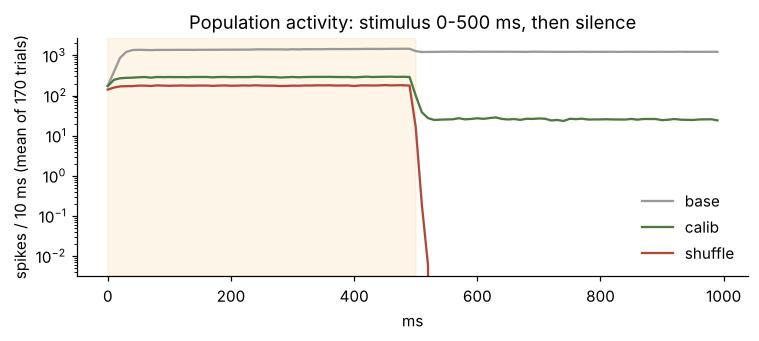

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for m, col in [('base', '#999'), ('calib', '#4a7a3d'), ('shuffle', '#b0483a')]:
    d = np.load(R/f'readout/trials_{m}.npz', allow_pickle=True)
    pop = d['pop']; t = np.arange(pop.shape[1]) * 10
    ax.plot(t, pop.mean(0), color=col, label=m)
ax.axvspan(0, 500, color='#f2b13c', alpha=.12); ax.set(xlabel='ms', ylabel='spikes / 10 ms (mean of 170 trials)', yscale='log')
ax.legend(frameon=False); ax.set_title('Population activity: stimulus 0-500 ms, then silence'); plt.tight_layout()

Interactive version with the brain graph, heat maps and these confusion matrices: the Week 2 Connectome Explorer (`artifact/connectome_explorer.html`).